# Person A — Exploratory data analysis

**Issue:** #2 · **Scope:** Sprint 2 EDA only

This notebook describes the shared UCI student-success data using the approved feature scenarios from Sprint 1. Outcome-conditioned exploration uses **only the frozen training rows**. The held-out test labels are not inspected or used for feature selection or model decisions.

Run from the repository root after `pip install -r requirements.txt`:

```bash
PYTHONPATH=src jupyter nbconvert --to notebook --execute --inplace notebooks/01_person_a_eda.ipynb
```

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make execution reliable from the repository root or from notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").exists(), "Run this notebook from the project repository."
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from student_success import CLASS_LABELS, TARGET_COLUMN
from student_success.data import load_dataset
from student_success.features import get_feature_columns
from student_success.split import load_split_indices

FIGURE_DIR = PROJECT_ROOT / "figures" / "eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_ORDER = list(CLASS_LABELS)
COLORS = {"Dropout": "#c44e52", "Enrolled": "#dd8452", "Graduate": "#4c9a6a"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## Load the shared data and verify the EDA contract

The checks below confirm that the committed dataset and frozen split have the expected structure. The `test_index` is used only to confirm the split is complete and disjoint; no test outcomes are analysed.

In [2]:
frame = load_dataset()
train_index, test_index = load_split_indices(PROJECT_ROOT / "data" / "processed" / "split_indices.npz")

# Reproducibility and leakage-safety checks.
assert frame.shape == (4424, 37)
assert frame[TARGET_COLUMN].isna().sum() == 0
assert set(frame[TARGET_COLUMN]) == set(TARGET_ORDER)
assert len(train_index) == 3539 and len(test_index) == 885
assert set(train_index).isdisjoint(test_index)
assert set(train_index).union(test_index) == set(range(len(frame)))
assert frame.isna().sum().sum() == 0
assert frame.duplicated().sum() == 0

enrollment_columns = get_feature_columns("enrollment_only")
first_semester_columns = get_feature_columns("first_semester")
assert TARGET_COLUMN not in enrollment_columns + first_semester_columns
assert not any("Curricular units 2nd sem" in column for column in first_semester_columns)
assert not any("Curricular units 1st sem" in column for column in enrollment_columns)

# All following target-based summaries and plots use this training frame only.
train = frame.iloc[train_index].copy()

print(f"Shared dataset: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
print(f"Training rows used for EDA: {len(train):,}")
print(f"Approved inputs: {len(enrollment_columns)} enrollment-only; {len(first_semester_columns)} after first semester")
print("Reproducibility checks passed: dataset, labels, split, missing values, duplicates, and scenario boundaries.")

Shared dataset: 4,424 rows × 37 columns
Training rows used for EDA: 3,539
Approved inputs: 18 enrollment-only; 24 after first semester
Reproducibility checks passed: dataset, labels, split, missing values, duplicates, and scenario boundaries.


## Outcome distribution

The recorded outcome is moderately imbalanced. The chart reports counts and percentages from training data only.

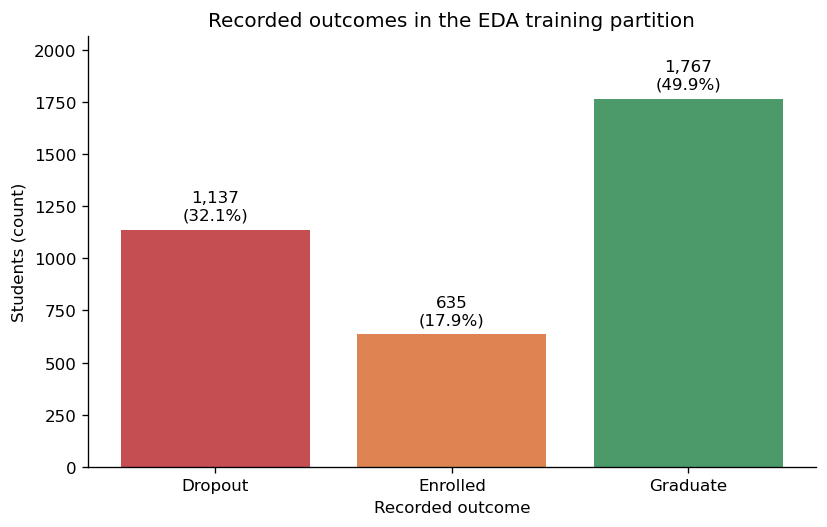

,count,percent
Target,,
Dropout,1137,32.1
Enrolled,635,17.9
Graduate,1767,49.9


In [3]:
outcome_counts = train[TARGET_COLUMN].value_counts().reindex(TARGET_ORDER)
outcome_percentages = outcome_counts / len(train) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(TARGET_ORDER, outcome_counts, color=[COLORS[label] for label in TARGET_ORDER])
ax.set_title("Recorded outcomes in the EDA training partition")
ax.set_xlabel("Recorded outcome")
ax.set_ylabel("Students (count)")
for bar, count, pct in zip(bars, outcome_counts, outcome_percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 35, f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, outcome_counts.max() * 1.17)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_outcome_distribution.png", bbox_inches="tight")
plt.show()

pd.DataFrame({"count": outcome_counts, "percent": outcome_percentages.round(1)})

## Enrollment-only characteristics

Age at enrollment and admission grade are approved enrollment-only numeric inputs. Boxplots show distributions rather than a causal effect.

/var/folders/bf/0d5p0sh13jvbv7s7j63rn5400000gn/T/ipykernel_95791/905211227.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)
/var/folders/bf/0d5p0sh13jvbv7s7j63rn5400000gn/T/ipykernel_95791/905211227.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)


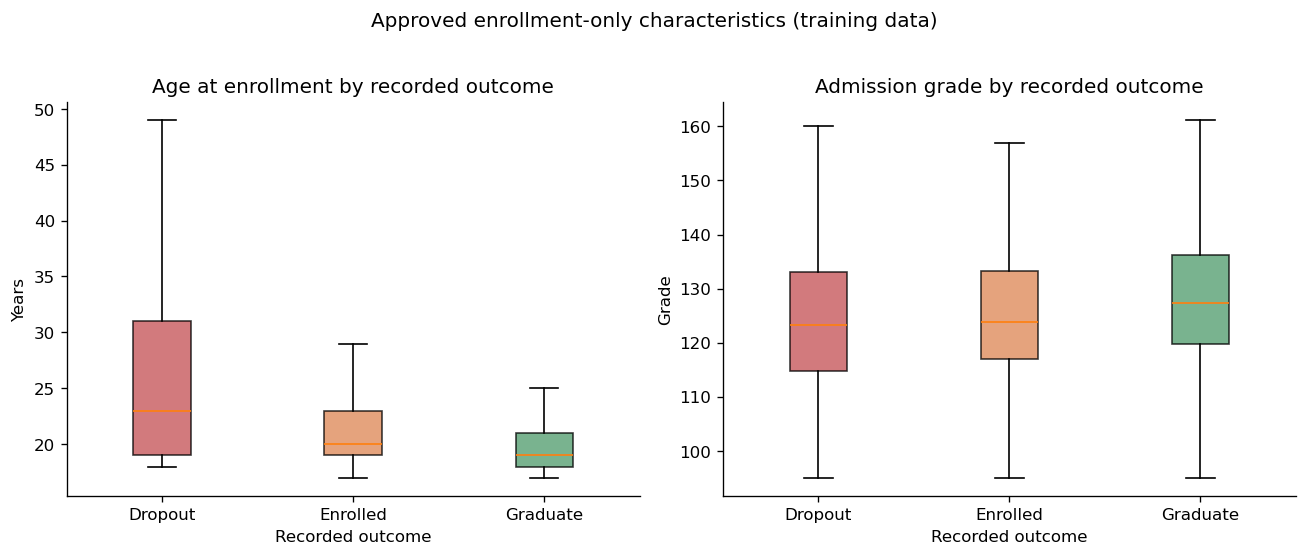

,Age at enrollment,Admission grade
Target,,
Dropout,23.0,123.3
Enrolled,20.0,123.9
Graduate,19.0,127.3


In [4]:
enrollment_measures = ["Age at enrollment", "Admission grade"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, column in zip(axes, enrollment_measures):
    values = [train.loc[train[TARGET_COLUMN] == label, column] for label in TARGET_ORDER]
    plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)
    for patch, label in zip(plot["boxes"], TARGET_ORDER):
        patch.set_facecolor(COLORS[label])
        patch.set_alpha(0.75)
    ax.set_title(f"{column} by recorded outcome")
    ax.set_xlabel("Recorded outcome")
    ax.set_ylabel("Years" if column == "Age at enrollment" else "Grade")
fig.suptitle("Approved enrollment-only characteristics (training data)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_enrollment_characteristics.png", bbox_inches="tight")
plt.show()

train.groupby(TARGET_COLUMN, observed=True)[enrollment_measures].median().reindex(TARGET_ORDER)

## Course composition

`Course` is a UCI-coded categorical enrollment variable. To keep the chart readable, it shows the eight most common course codes in the training data. Percentages within each bar sum to 100%; this is descriptive, not a ranking of courses.

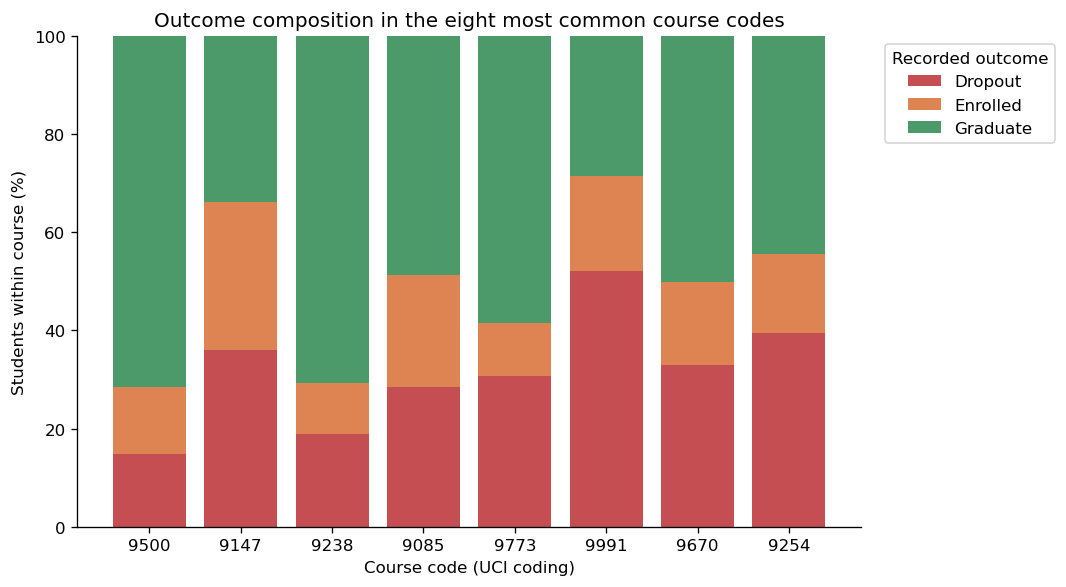

Target,Dropout,Enrolled,Graduate
Course,,,
9500,14.8,13.7,71.5
9147,36.1,30.1,33.8
9238,18.9,10.3,70.8
9085,28.5,22.7,48.7
9773,30.7,10.9,58.4
9991,52.1,19.4,28.6
9670,32.9,16.9,50.2
9254,39.4,16.2,44.4


In [5]:
top_courses = train["Course"].value_counts().head(8).index
course_composition = (
    pd.crosstab(train.loc[train["Course"].isin(top_courses), "Course"], train.loc[train["Course"].isin(top_courses), TARGET_COLUMN], normalize="index")
    .reindex(index=top_courses, columns=TARGET_ORDER, fill_value=0)
    * 100
)

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(course_composition))
for label in TARGET_ORDER:
    ax.bar(course_composition.index.astype(str), course_composition[label], bottom=bottom, label=label, color=COLORS[label])
    bottom += course_composition[label].to_numpy()
ax.set_title("Outcome composition in the eight most common course codes")
ax.set_xlabel("Course code (UCI coding)")
ax.set_ylabel("Students within course (%)")
ax.set_ylim(0, 100)
ax.legend(title="Recorded outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_course_outcome_composition.png", bbox_inches="tight")
plt.show()

course_composition.round(1)

## First-semester academic performance

These measures belong only to the `first_semester` scenario. Valid zero values are retained: a zero approved-unit count is not treated as missing.

/var/folders/bf/0d5p0sh13jvbv7s7j63rn5400000gn/T/ipykernel_95791/2901831702.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)
/var/folders/bf/0d5p0sh13jvbv7s7j63rn5400000gn/T/ipykernel_95791/2901831702.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)


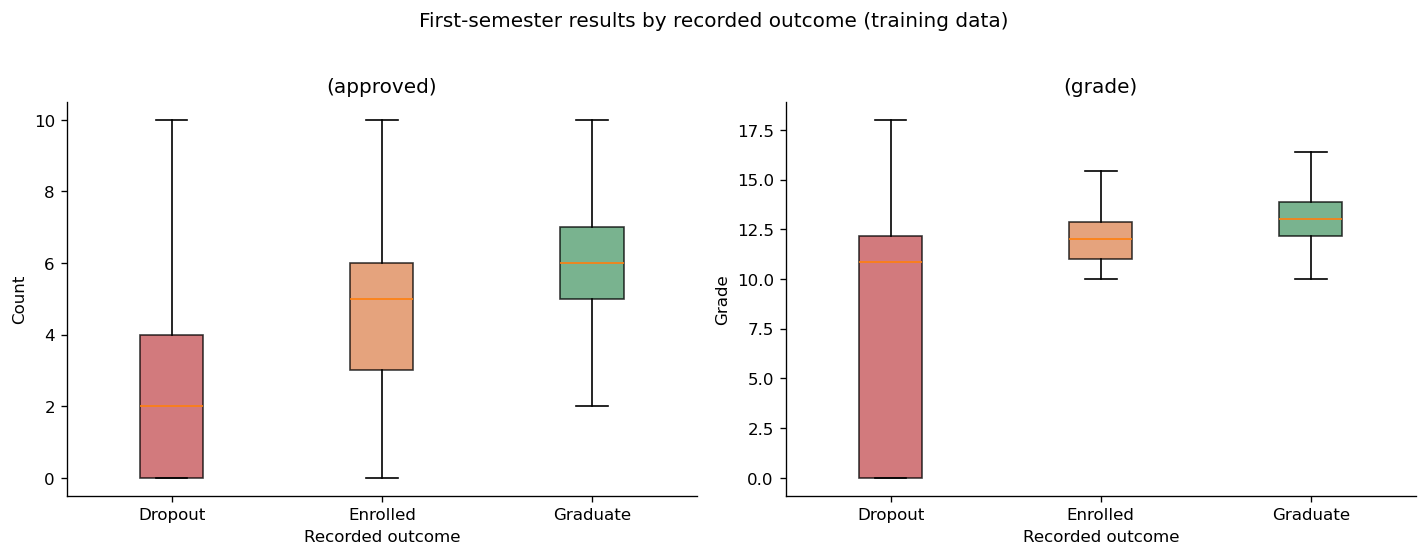

,Curricular units 1st sem (approved),Curricular units 1st sem (grade)
Target,,
Dropout,2.0,10.833333
Enrolled,5.0,12.000000
Graduate,6.0,13.000000


In [6]:
semester_measures = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, semester_measures):
    values = [train.loc[train[TARGET_COLUMN] == label, column] for label in TARGET_ORDER]
    plot = ax.boxplot(values, labels=TARGET_ORDER, patch_artist=True, showfliers=False)
    for patch, label in zip(plot["boxes"], TARGET_ORDER):
        patch.set_facecolor(COLORS[label])
        patch.set_alpha(0.75)
    ax.set_title(column.replace("Curricular units 1st sem ", ""))
    ax.set_xlabel("Recorded outcome")
    ax.set_ylabel("Count" if "approved" in column else "Grade")
fig.suptitle("First-semester results by recorded outcome (training data)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_first_semester_performance.png", bbox_inches="tight")
plt.show()

train.groupby(TARGET_COLUMN, observed=True)[semester_measures].median().reindex(TARGET_ORDER)

## Relationship between academic activity and approved units

This scatterplot gives a compact view of a useful first-semester relationship. The overlapping points and outcome groups show association only; they do not establish a threshold, cause, or individual prediction rule.

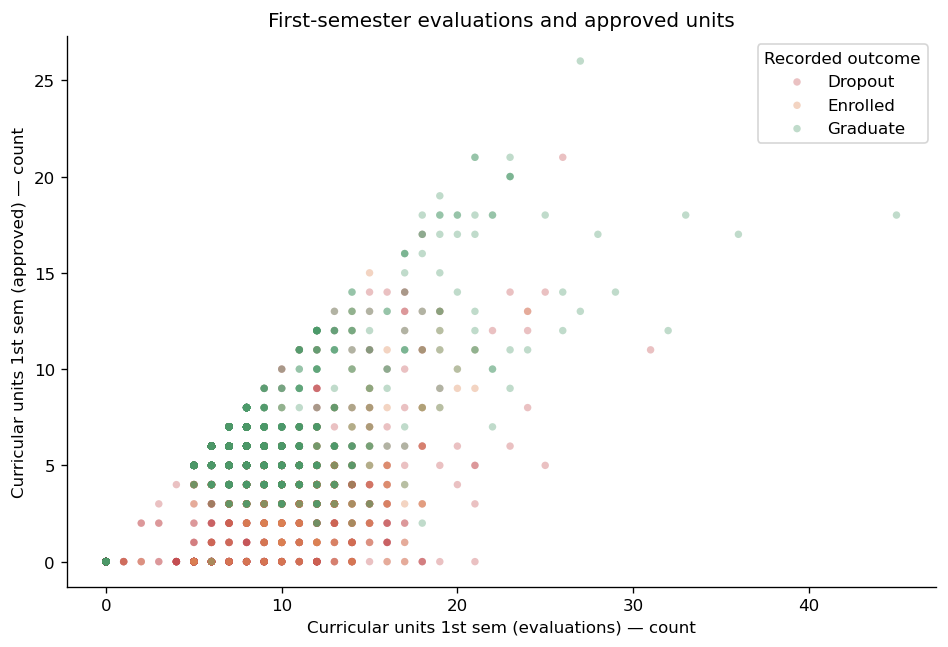

Target
Dropout     40.5
Enrolled     9.0
Graduate     3.7
Name: Share with zero approved units (%), dtype: float64

In [7]:
x_column = "Curricular units 1st sem (evaluations)"
y_column = "Curricular units 1st sem (approved)"
fig, ax = plt.subplots(figsize=(8, 5.5))
for label in TARGET_ORDER:
    subset = train.loc[train[TARGET_COLUMN] == label]
    ax.scatter(subset[x_column], subset[y_column], label=label, color=COLORS[label], alpha=0.35, s=20, edgecolors="none")
ax.set_title("First-semester evaluations and approved units")
ax.set_xlabel("Curricular units 1st sem (evaluations) — count")
ax.set_ylabel("Curricular units 1st sem (approved) — count")
ax.legend(title="Recorded outcome")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_evaluations_vs_approved_units.png", bbox_inches="tight")
plt.show()

zero_approved = (
    pd.crosstab(train[y_column].eq(0), train[TARGET_COLUMN], normalize="columns")
    .reindex(index=[True], columns=TARGET_ORDER)
    .iloc[0]
    .mul(100)
    .round(1)
)
zero_approved.rename("Share with zero approved units (%)")

## Findings and limits

### Findings from the training partition

1. **Graduate is the largest class (49.9%), while Enrolled is the smallest (17.9%).** A simple accuracy score could therefore overstate performance on the smaller classes; later model evaluation should report macro-F1 and class-specific recall, especially for Dropout.
2. **First-semester results differ strongly across recorded outcomes.** Median approved units are 2 for Dropout, 5 for Enrolled, and 6 for Graduate. Also, 40.5% of Dropout records have zero approved units, compared with 9.0% of Enrolled and 3.7% of Graduate records. This makes first-semester performance an important descriptive signal for the after-first-semester scenario only.
3. **The outcome groups also differ in some enrollment characteristics, but overlap remains.** The median age at enrollment is 23 for Dropout, 20 for Enrolled, and 19 for Graduate; Graduate has the highest median admission grade (127.3). These patterns are associations in this dataset, not causes or decision rules.

### Limits and leakage safeguards

- This is a three-class, retrospective recorded-outcome dataset. It contains no individual dropout dates and cannot show when an intervention would have been possible.
- Outcome-conditioned EDA here uses only the frozen training partition. The held-out test labels remain untouched for the later final comparison.
- `Curricular units 1st sem ...` features are intentionally excluded from `enrollment_only`; all second-semester fields, the target, and time-ambiguous finance/macro fields remain outside both approved scenarios.
- Course codes are categories from the UCI data, not course-quality scores. Group differences may also reflect unmeasured factors. Sensitive or administrative variables should not be interpreted as causal or used for punitive decisions.
- The shared data has no missing cells or duplicate rows, but this does not prove that all real-world deployment inputs will be complete or measured at the same time.

## Reproduce

The notebook writes five PNG files to `figures/eda/`. It does not change the shared split, feature lists, preprocessing, or any model artifact. Re-run the command at the top of this notebook after changing the dataset or environment.